# CornGuard: YOLOv8 Bulai (satu notebook, dari training sampai ekspor)

Satu notebook, satu alur, dijalankan **dari atas ke bawah**. Dataset: Roboflow *bulai-jagung* **v7** (YOLOv8, Stretch 640x640, CC BY 4.0).

| Bagian | Isi |
|---|---|
| 1 | Setup (install, mount Drive) |
| 2 | Konfigurasi (semua pengaturan di satu sel) |
| 3 | Dataset (unzip, filter hanya Bulai, verifikasi, `data.yaml`) |
| 4 | Training |
| 5 | Evaluasi (grafik, metrik valid dan test, analisis kesalahan, uji foto tanpa Bulai) |
| 6 | Ekspor ONNX dan verifikasi |
| 7 | *(Opsional)* Diagnosis dataset |

**Cara pakai**
- **Training + evaluasi + ekspor:** jalankan semua dari atas. Wajib GPU (Runtime > Change runtime type > T4 GPU). Training memakan beberapa jam.
- **Hanya evaluasi/ekspor model yang sudah ada:** di bagian 2 set `RUN_TRAINING = False` dan isi `RUN_NAME` dengan nama run yang mau dinilai, lalu jalankan semua dari atas. Bagian 4 otomatis dilewati.
- **Colab terputus saat training:** jalankan ulang bagian 1 sampai 3, set `RESUME = True` di bagian 2, lalu jalankan bagian 4.

## 1. Setup
Install Ultralytics dan mount Google Drive.

**Selesai kalau:** muncul `Mounted at /content/drive` dan baris `Setup complete`.

In [3]:
!nvidia-smi
!pip install -q ultralytics

from google.colab import drive
drive.mount('/content/drive')

import ultralytics
ultralytics.checks()

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 42.4/112.6 GB disk)


## 2. Konfigurasi
Semua pengaturan ada di sini. Bagian lain tidak perlu diubah.

In [4]:
# --- lokasi ---
ZIP_PATH    = "/content/drive/MyDrive/Dataset Bulai-YOLO/BULAI JAGUNG.v7i.yolov8.zip"
DATASET_DIR = "/content/dataset"
DRIVE_OUT   = "/content/drive/MyDrive/Dataset Bulai-YOLO/training_bulai"   # hasil training disimpan di sini

# --- mode ---
RUN_TRAINING = True    # False = lewati training, hanya evaluasi/ekspor run yang sudah ada
RESUME       = False   # True  = lanjutkan training yang terputus (butuh last.pt)

# --- data ---
SEED           = 42
BULAI_CLASS_ID = "0"   # index kelas Bulai di data.yaml asli
BG_RATIO       = 0.10  # foto tanpa Bulai (background) yang ikut ke TRAIN, sebagai fraksi dari jumlah foto Bulai.
                       # Tujuannya mengurangi deteksi palsu di rumput/daun sehat. Set 0 untuk meniru run lama.

# --- training ---
MODEL_NAME = "yolov8s.pt"
EPOCHS     = 150       # batas atas; early stopping (PATIENCE) bisa menghentikan lebih awal
PATIENCE   = 50
IMGSZ      = 960       # foto dataset 640 px; 960 memberi hasil lebih baik daripada 640 di run sebelumnya
BATCH      = 16        # kalau muncul CUDA out of memory, turunkan ke 8
RUN_NAME   = "bulai_yolov8s_v7_bg"   # nama run; ganti kalau mau run baru supaya hasil lama tidak tertimpa

RUN_DIR = f"{DRIVE_OUT}/{RUN_NAME}"
print("Hasil akan disimpan di:", RUN_DIR)

Hasil akan disimpan di: /content/drive/MyDrive/Dataset Bulai-YOLO/training_bulai/bulai_yolov8s_v7_bg


## 3. Dataset
### 3.1 Unzip
Dataset diambil dari Drive ke `/content/dataset` (folder ini terhapus tiap sesi baru, jadi bagian ini selalu dijalankan).

In [5]:
import zipfile, shutil, os

if os.path.exists(DATASET_DIR):
    shutil.rmtree(DATASET_DIR)

with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    z.extractall(DATASET_DIR)

for split in ["train", "valid", "test"]:
    print(f"{split}: {len(os.listdir(f'{DATASET_DIR}/{split}/images'))} gambar (asli, 3 kelas)")

train: 3217 gambar (asli, 3 kelas)
valid: 322 gambar (asli, 3 kelas)
test: 169 gambar (asli, 3 kelas)


### 3.2 Filter: hanya kelas Bulai
- Kelas `Sehat-Muda` dan `sehat Tua` dibuang dari label.
- **train:** foto tanpa Bulai dibuang, kecuali sebagian kecil (`BG_RATIO`) yang dipertahankan sebagai *background* supaya model belajar bahwa daun sehat/rumput berarti tanpa kotak.
- **valid dan test:** tetap hanya foto Bulai (supaya metrik sebanding dengan run sebelumnya). Foto tanpa Bulai dipindah ke `valid_negatif/` dan `test_negatif/` untuk uji deteksi palsu di bagian 5.

In [6]:
import random
random.seed(SEED)

def hapus_pasangan(img_dir, lbl_dir, fname):
    base = os.path.splitext(fname)[0]
    for ext in [".jpg", ".jpeg", ".png"]:
        p = os.path.join(img_dir, base + ext)
        if os.path.exists(p):
            os.remove(p)
            break
    os.remove(os.path.join(lbl_dir, fname))

for split in ["train", "valid", "test"]:
    img_dir = f"{DATASET_DIR}/{split}/images"
    lbl_dir = f"{DATASET_DIR}/{split}/labels"
    kept, boxes, kosong = 0, 0, []

    for fname in sorted(os.listdir(lbl_dir)):
        lbl_path = os.path.join(lbl_dir, fname)
        with open(lbl_path) as f:
            lines = [l for l in f.read().splitlines() if l.strip()]
        bulai = [l for l in lines if l.split()[0] == BULAI_CLASS_ID]
        with open(lbl_path, "w") as f:                       # tulis ulang: hanya Bulai
            f.write("\n".join(bulai) + ("\n" if bulai else ""))
        if bulai:
            kept += 1; boxes += len(bulai)
        else:
            kosong.append(fname)

    if split == "train":
        n_bg = int(kept * BG_RATIO)
        simpan = set(random.sample(kosong, min(n_bg, len(kosong))))
        for fname in kosong:
            if fname not in simpan:
                hapus_pasangan(img_dir, lbl_dir, fname)
        print(f"{split}: foto Bulai={kept}, background dipertahankan={len(simpan)}, dibuang={len(kosong)-len(simpan)}, box Bulai={boxes}")
    else:
        neg_img = f"{DATASET_DIR}/{split}_negatif/images"
        os.makedirs(neg_img, exist_ok=True)
        for fname in kosong:
            base = os.path.splitext(fname)[0]
            for ext in [".jpg", ".jpeg", ".png"]:
                p = os.path.join(img_dir, base + ext)
                if os.path.exists(p):
                    shutil.move(p, os.path.join(neg_img, base + ext))
                    break
            os.remove(os.path.join(lbl_dir, fname))
        print(f"{split}: foto Bulai={kept}, dipindah ke {split}_negatif={len(kosong)}, box Bulai={boxes}")

train: foto Bulai=1190, background dipertahankan=119, dibuang=1908, box Bulai=24145
valid: foto Bulai=107, dipindah ke valid_negatif=215, box Bulai=2300
test: foto Bulai=68, dipindah ke test_negatif=101, box Bulai=1220


### 3.3 Verifikasi dan `data.yaml`
**Selesai kalau:** semua split berstatus `OK` dan isi `data.yaml` menunjukkan `nc: 1` dan `names: [Bulai]`.

In [7]:
import yaml

for split in ["train", "valid", "test"]:
    img_dir = f"{DATASET_DIR}/{split}/images"
    lbl_dir = f"{DATASET_DIR}/{split}/labels"
    imgs = {os.path.splitext(f)[0] for f in os.listdir(img_dir)}
    lbls = {os.path.splitext(f)[0] for f in os.listdir(lbl_dir)}
    ids, kosong = set(), 0
    for f in os.listdir(lbl_dir):
        baris = [l for l in open(os.path.join(lbl_dir, f)) if l.strip()]
        kosong += (len(baris) == 0)
        ids |= {l.split()[0] for l in baris}
    status = "OK" if imgs == lbls and ids <= {"0"} else "!! CEK ULANG"
    print(f"{split}: gambar={len(imgs)}, label={len(lbls)}, label kosong (background)={kosong}, class-id={ids} -> {status}")

data_yaml = {
    "path": DATASET_DIR,
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 1,
    "names": ["Bulai"],
}
YAML_PATH = f"{DATASET_DIR}/data.yaml"
with open(YAML_PATH, "w") as f:
    yaml.dump(data_yaml, f, sort_keys=False)
print()
print(open(YAML_PATH).read())

train: gambar=1309, label=1309, label kosong (background)=119, class-id={'0'} -> OK
valid: gambar=107, label=107, label kosong (background)=0, class-id={'0'} -> OK
test: gambar=68, label=68, label kosong (background)=0, class-id={'0'} -> OK

path: /content/dataset
train: train/images
val: valid/images
test: test/images
nc: 1
names:
- Bulai



### 3.4 Cek visual
Empat foto train acak dengan kotak labelnya. Pastikan kotak menempel di gejala Bulai.

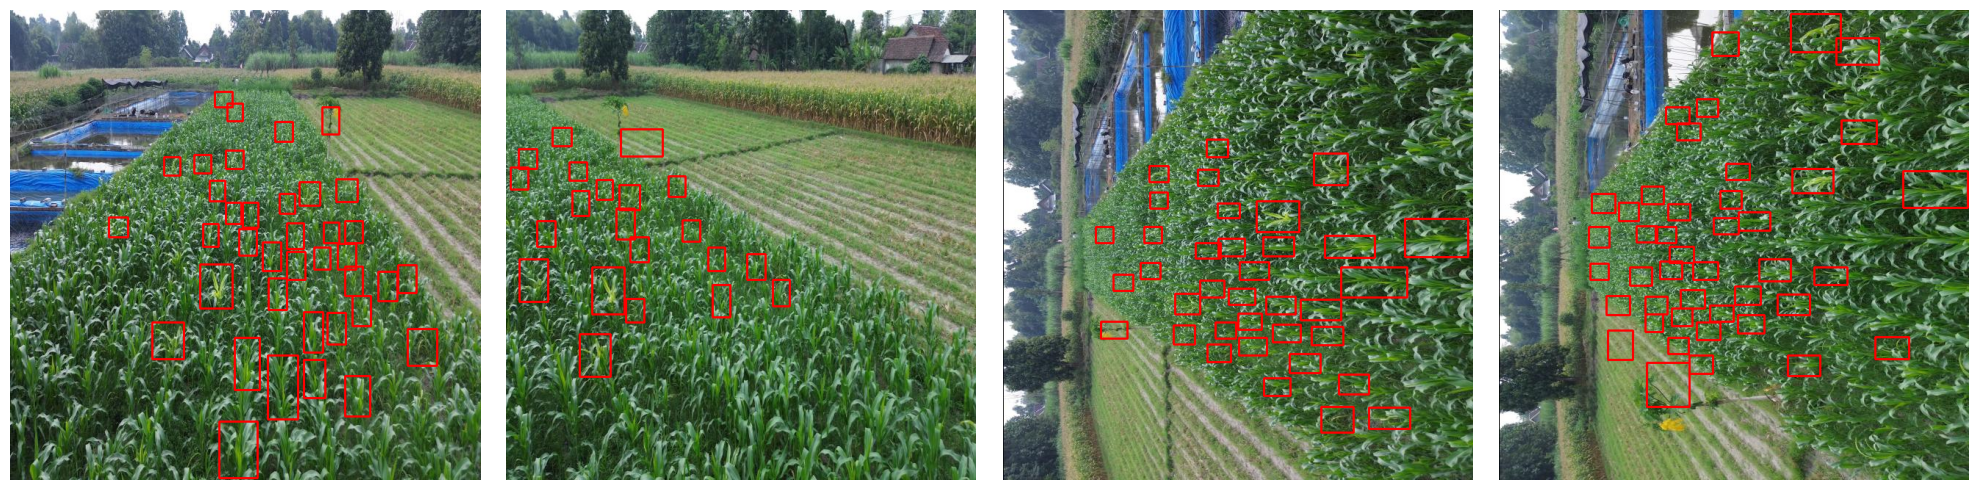

In [8]:
import cv2, glob
import numpy as np
import matplotlib.pyplot as plt

bertabel = [p for p in glob.glob(f"{DATASET_DIR}/train/images/*")
            if os.path.getsize(p.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt") > 0]
samples = random.sample(bertabel, 4)
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, img_path in zip(axes, samples):
    img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    lbl_path = img_path.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"
    for line in open(lbl_path):
        _, xc, yc, bw, bh = map(float, line.split())
        cv2.rectangle(img, (int((xc - bw/2) * w), int((yc - bh/2) * h)),
                      (int((xc + bw/2) * w), int((yc + bh/2) * h)), (255, 0, 0), 2)
    ax.imshow(img); ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Training
Hasil (`best.pt`, `last.pt`, grafik) disimpan langsung ke Drive di `RUN_DIR`.
- Kalau `RUN_TRAINING = False`, sel ini hanya memeriksa bahwa `best.pt` sudah ada.
- Sel ini **menolak berjalan** kalau `best.pt` untuk `RUN_NAME` itu sudah ada, supaya hasil lama tidak tertimpa. Ganti `RUN_NAME` kalau memang mau training baru.

**Selesai kalau:** muncul `best.pt ditemukan`.

In [9]:
import torch
try:
    from ultralytics import YOLO
except ImportError:
    !pip install -q ultralytics
    from ultralytics import YOLO

BEST_PT = f"{RUN_DIR}/weights/best.pt"

if not RUN_TRAINING:
    print("RUN_TRAINING = False -> training dilewati.")
elif RESUME:
    YOLO(f"{RUN_DIR}/weights/last.pt").train(resume=True)
else:
    if not torch.cuda.is_available():
        raise RuntimeError("GPU tidak terdeteksi. Di Colab: Runtime > Change runtime type > pilih GPU, "
                           "lalu Reconnect dan jalankan ulang dari bagian 1.")
    if os.path.exists(BEST_PT):
        raise FileExistsError(f"Sudah ada hasil training di {RUN_DIR}. Ganti RUN_NAME untuk training baru, "
                              "atau set RUN_TRAINING = False untuk hanya evaluasi.")
    print("GPU:", torch.cuda.get_device_name(0))
    model = YOLO(MODEL_NAME)
    model.train(
        data=YAML_PATH,
        epochs=EPOCHS,
        patience=PATIENCE,
        imgsz=IMGSZ,
        batch=BATCH,
        optimizer="auto",
        flipud=0.5,          # sama dengan run sebelumnya, supaya perbandingannya adil
        seed=SEED,
        device=0,            # paksa GPU; langsung error kalau GPU hilang
        project=DRIVE_OUT,
        name=RUN_NAME,
        exist_ok=True,
        plots=True,
    )

assert os.path.exists(BEST_PT), f"best.pt tidak ditemukan di {BEST_PT}. Cek RUN_NAME and DRIVE_OUT."
print("best.pt ditemukan:", BEST_PT)

GPU: Tesla T4
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=150, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=bulai_yolov8s_v7_bg, nbs=64, nms=None, opset=Non

## 5. Evaluasi
### 5.1 Grafik training
`results.png` (loss dan metrik per epoch), `confusion_matrix.png`, kurva Precision-Recall dan F1.

results.png


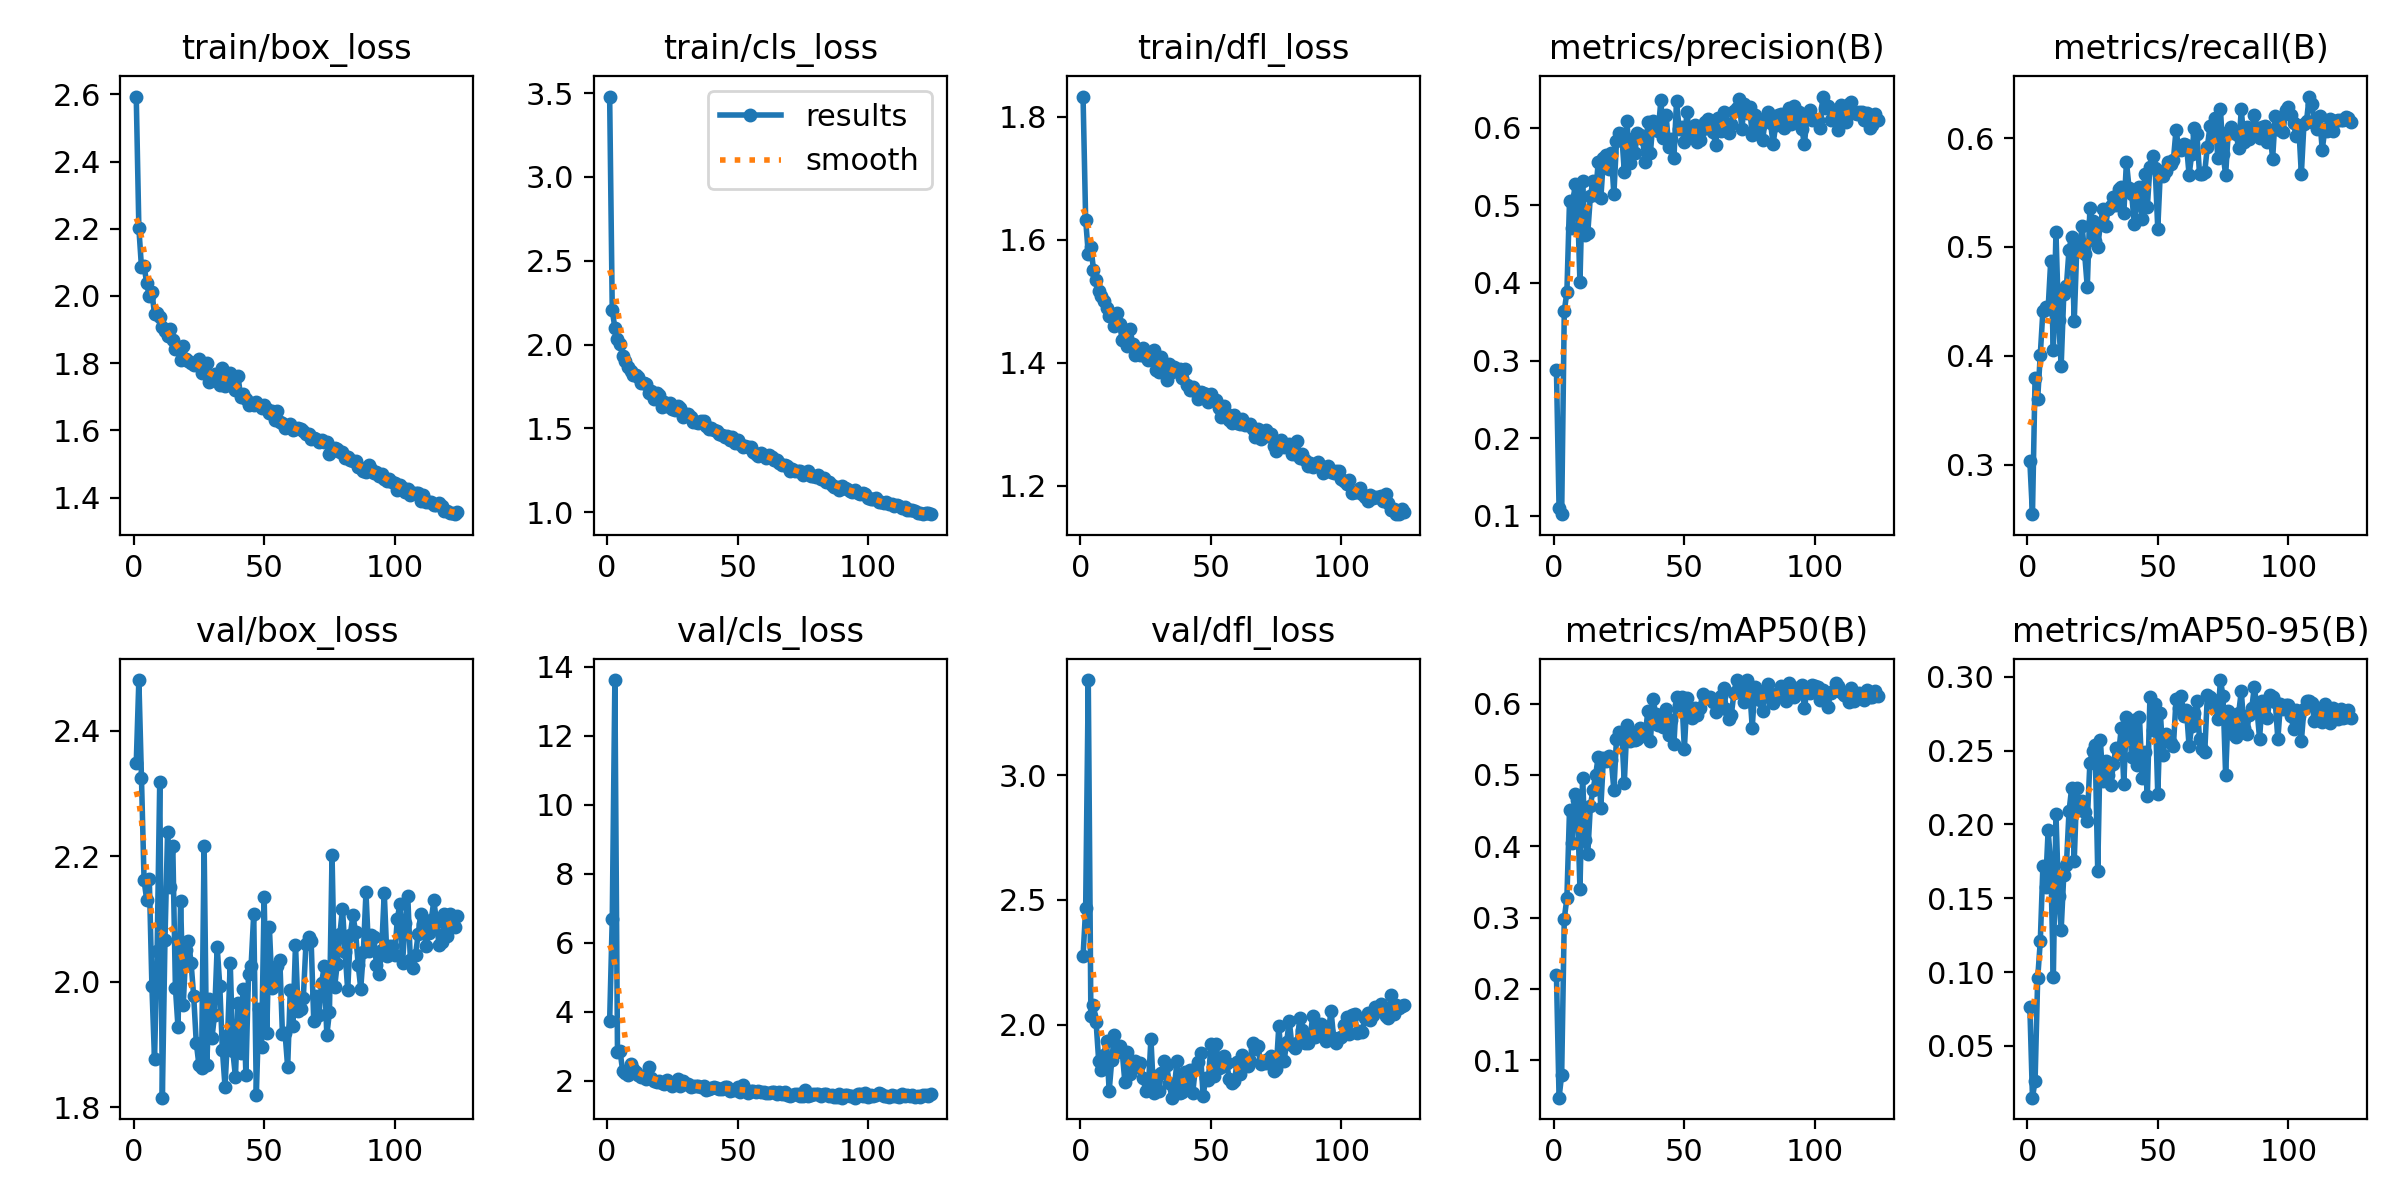

confusion_matrix.png


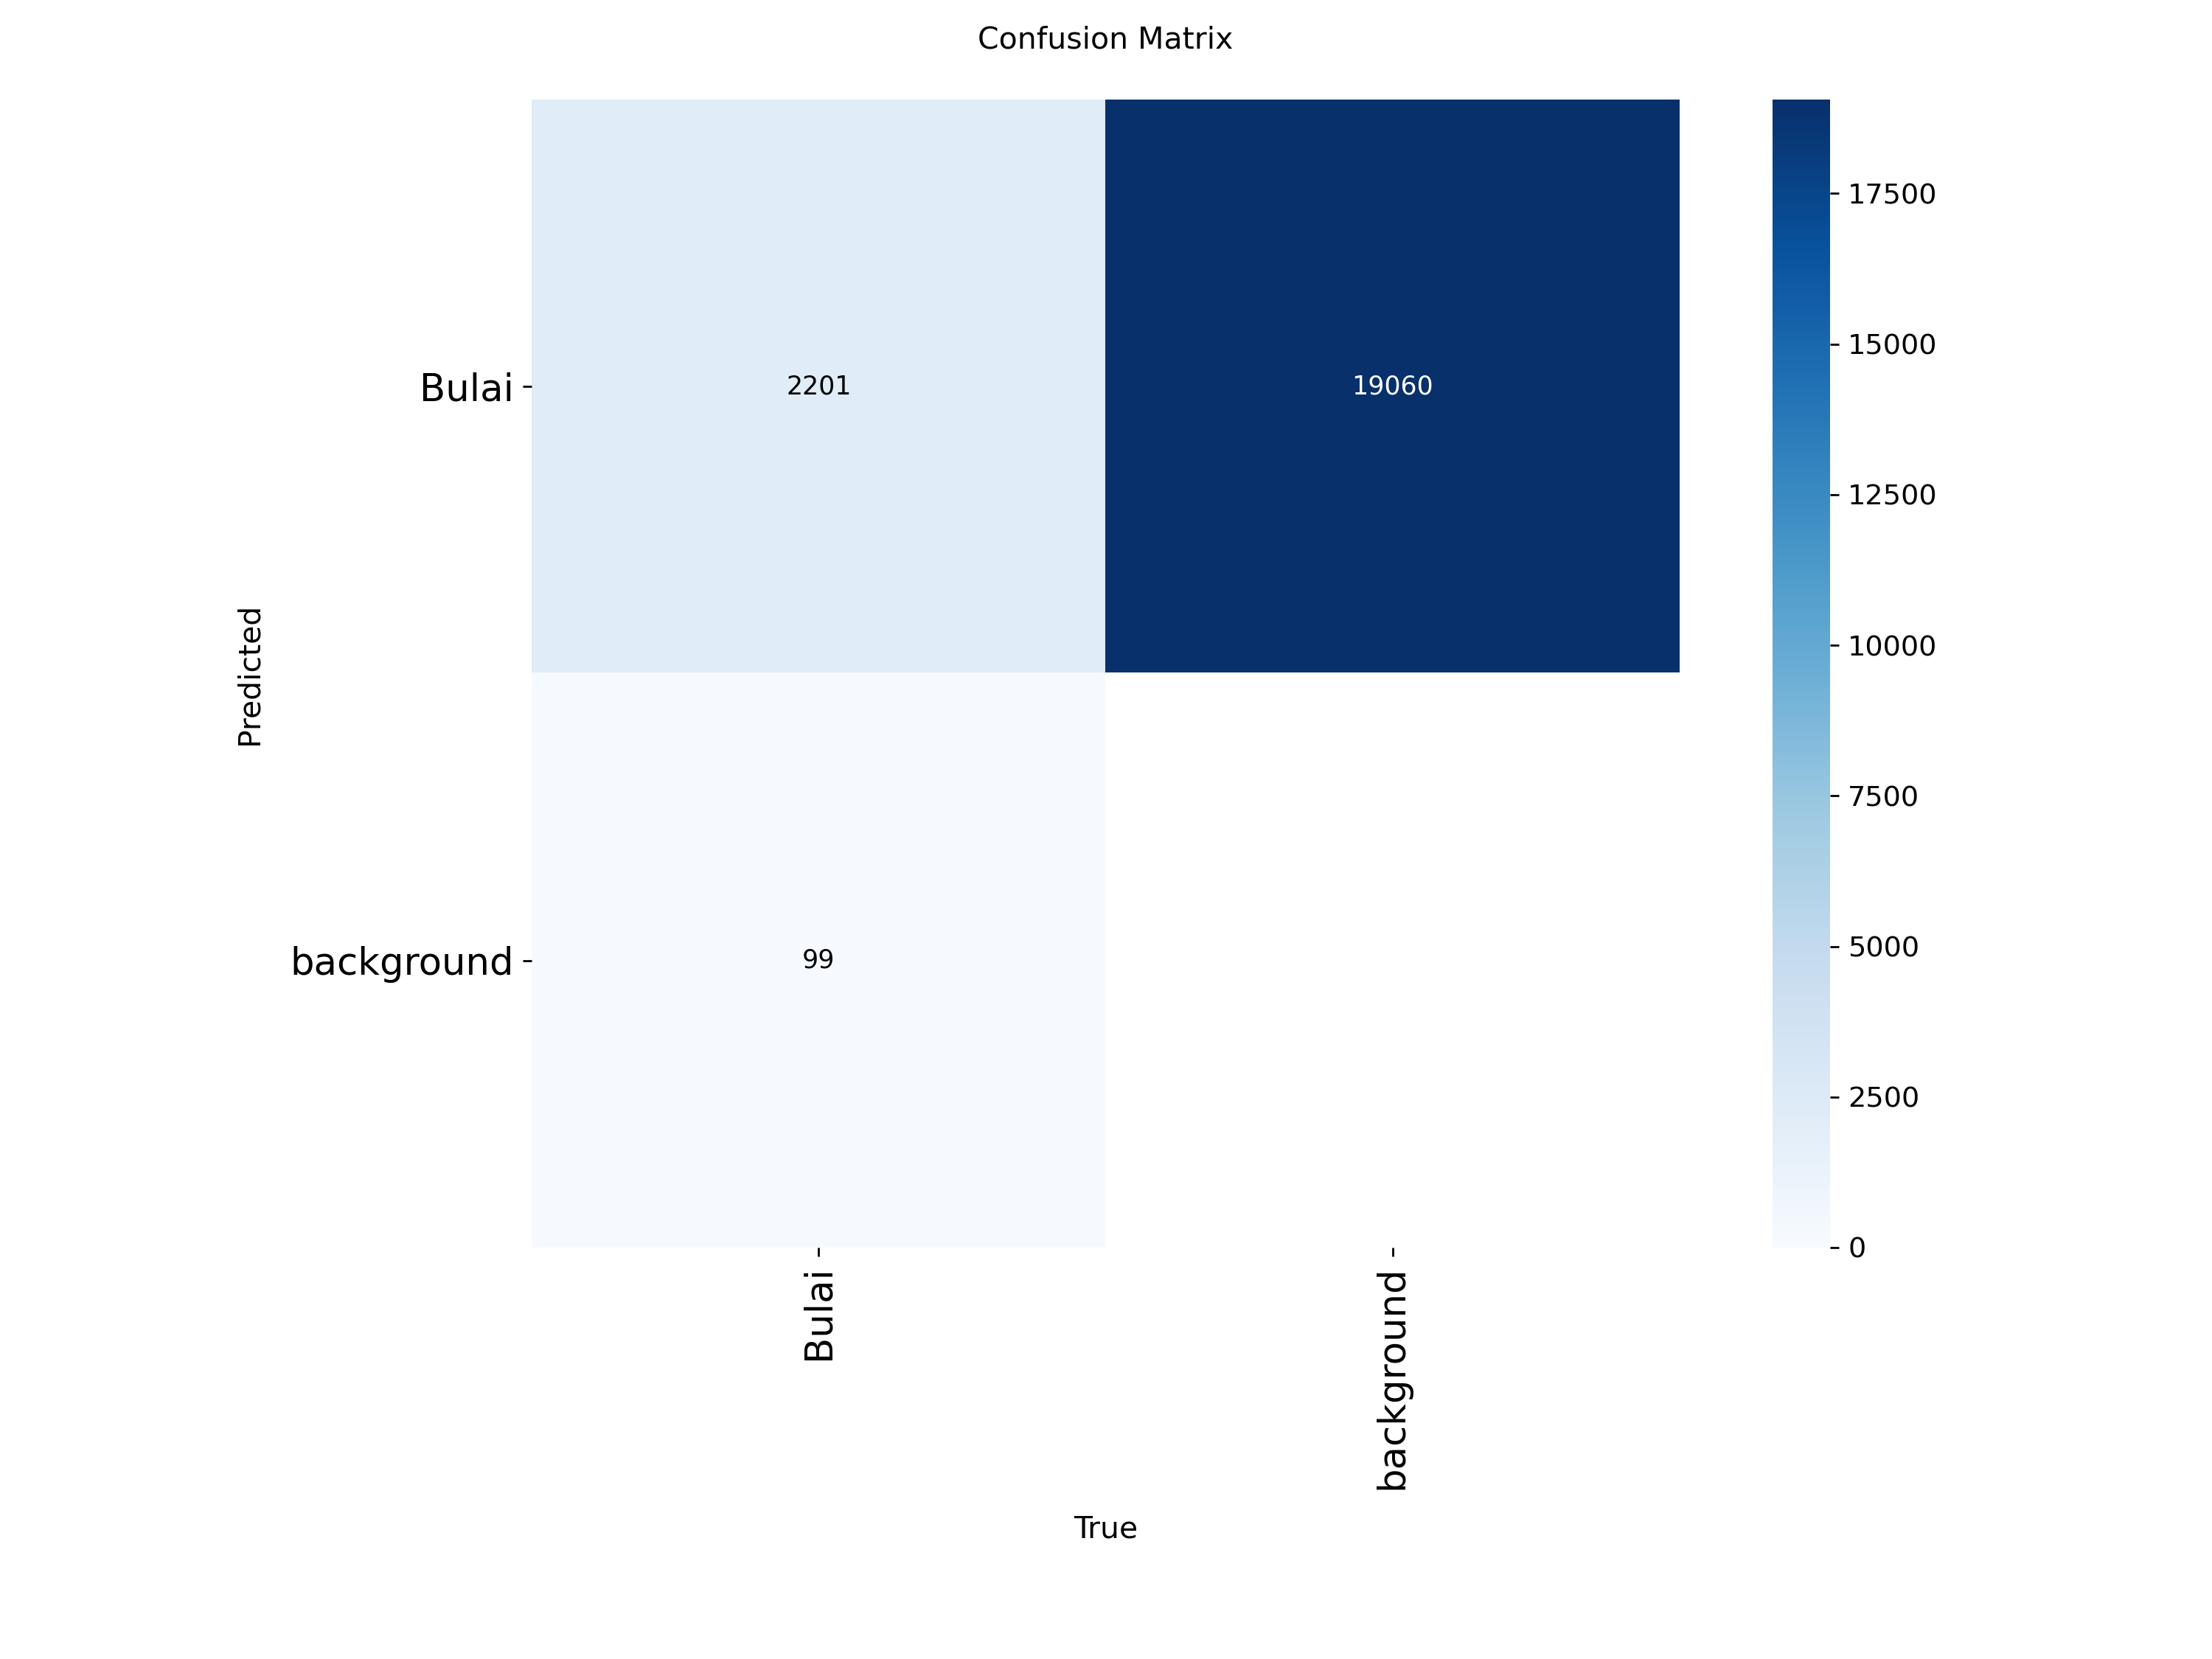

BoxPR_curve.png


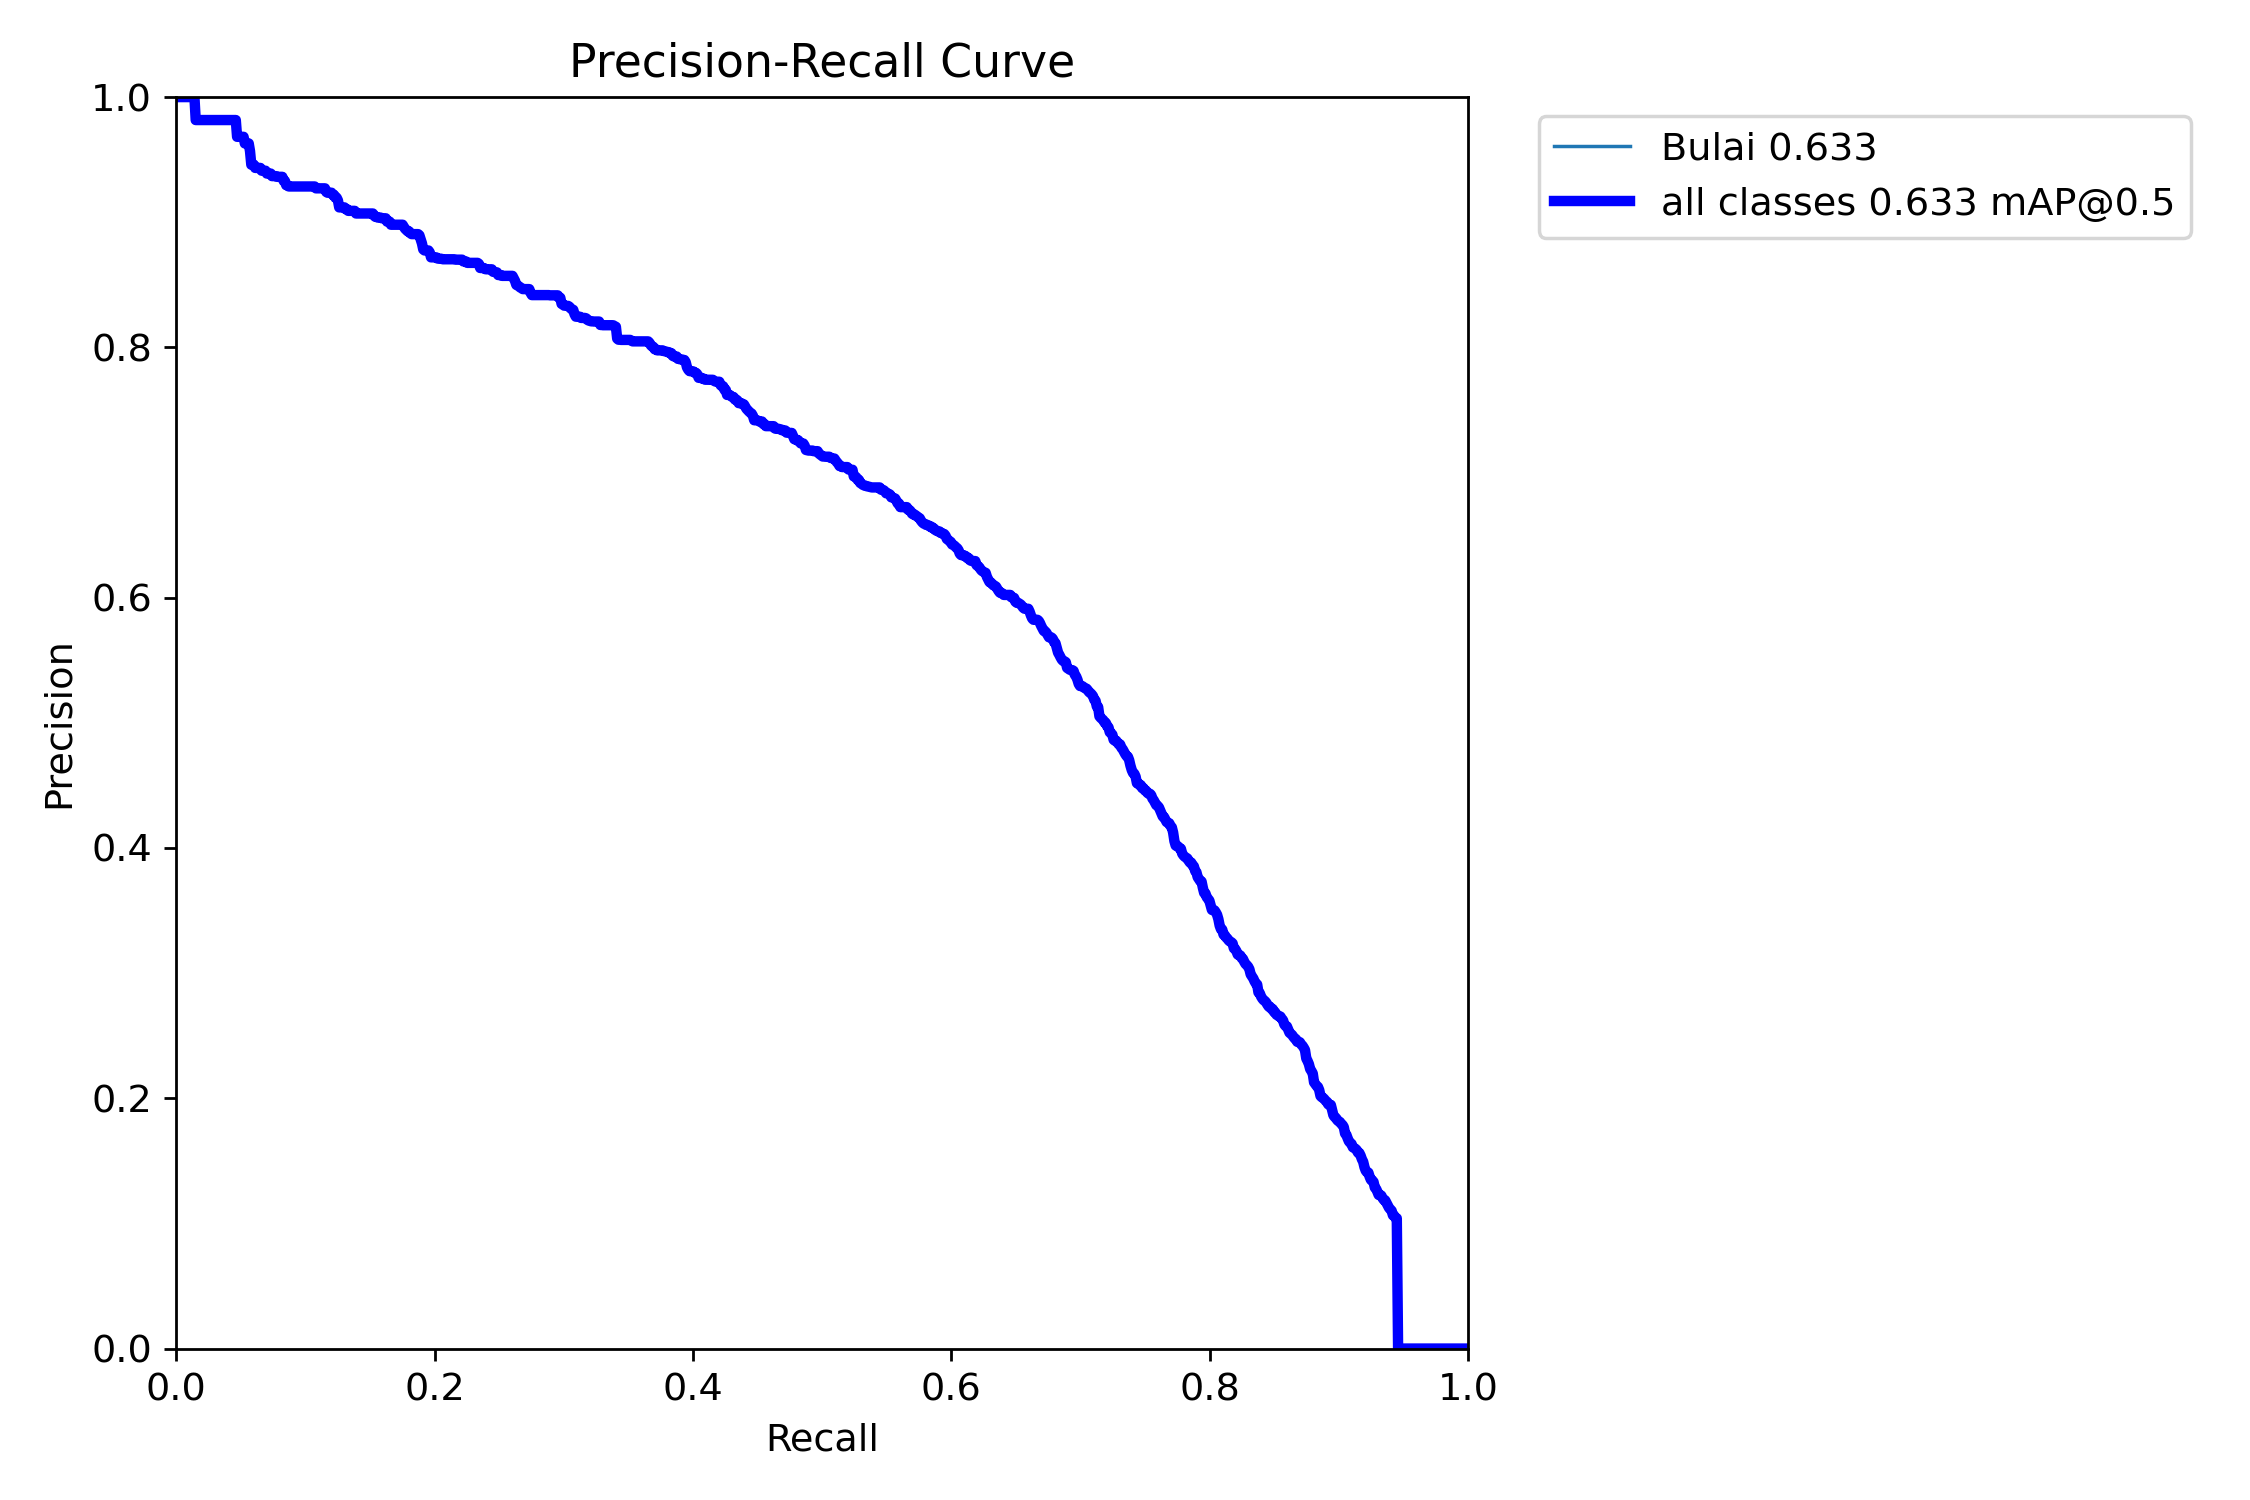

BoxF1_curve.png


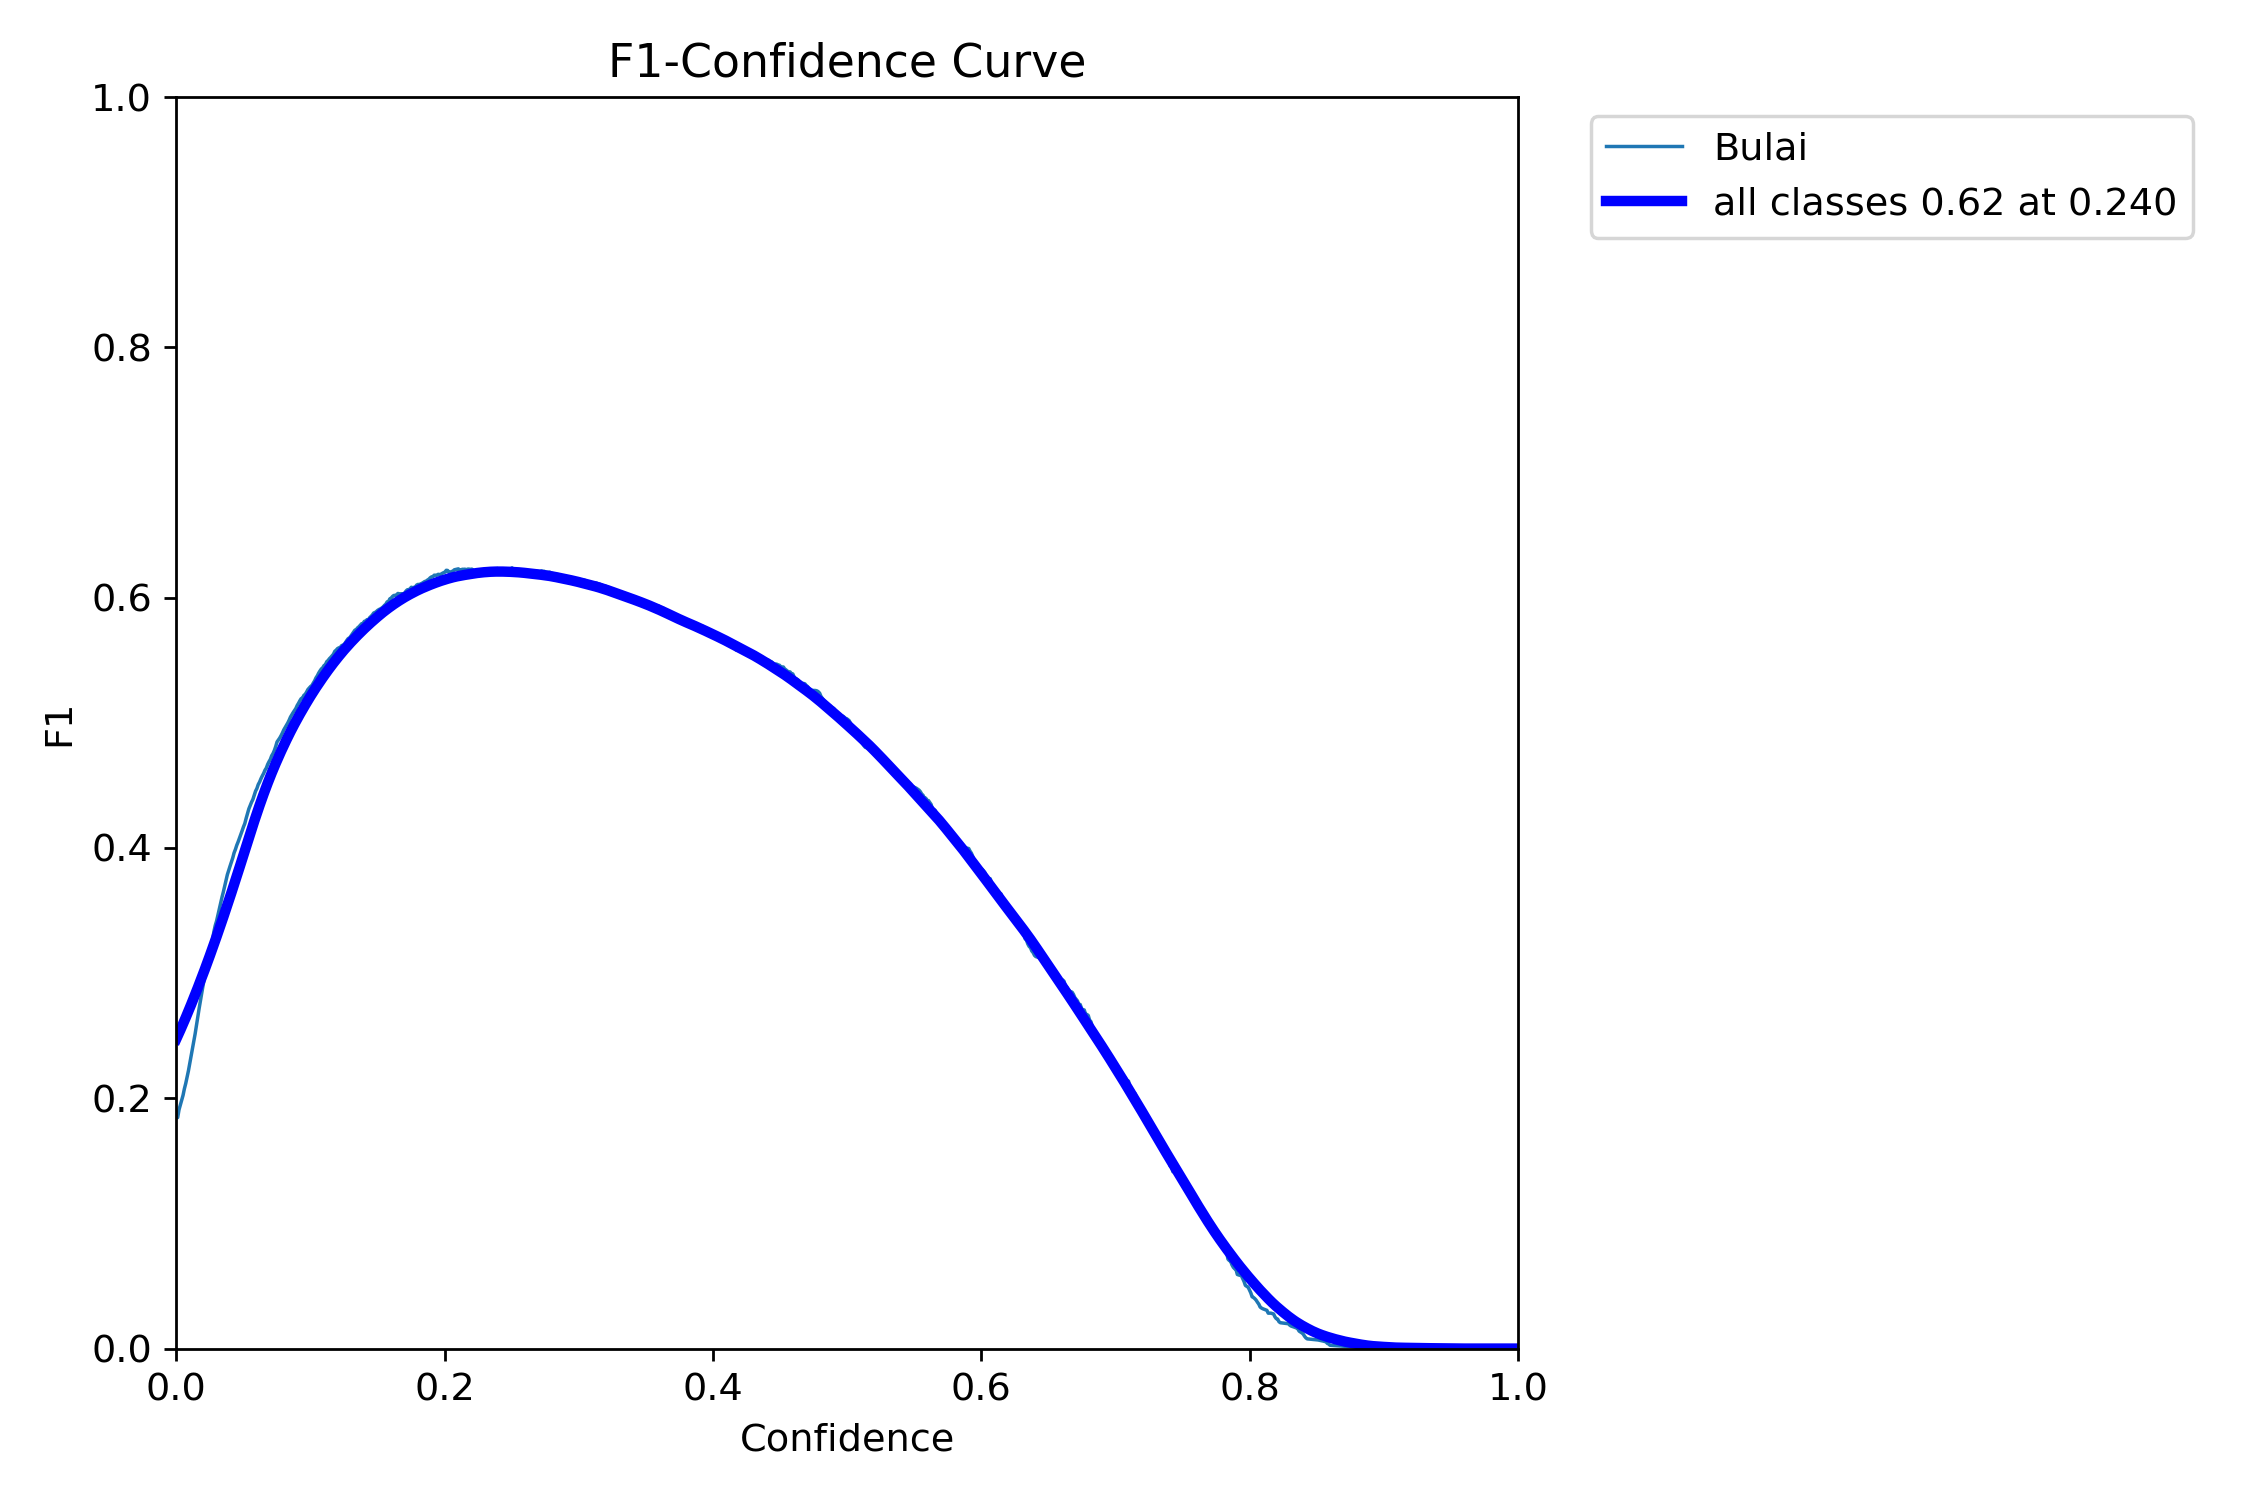

In [10]:
from IPython.display import Image, display

for n in ["results.png", "confusion_matrix.png", "BoxPR_curve.png", "BoxF1_curve.png"]:
    p = f"{RUN_DIR}/{n}"
    if os.path.exists(p):
        print(n); display(Image(filename=p, width=800))
    else:
        print(f"(tidak ada: {n})")

### 5.2 Metrik valid dan test
Threshold confidence (`CONF`) dipilih dari kurva F1 pada data **valid**, lalu dipakai untuk melaporkan hasil di data **test**. Data test tidak dipakai untuk memilih apa pun.

**Selesai kalau:** tabel ringkasan muncul dan `CONF` terisi. Tabel juga tersimpan ke Drive (`*_evaluasi.csv`).

In [11]:
import pandas as pd
from ultralytics import YOLO

best = YOLO(BEST_PT)

def jalankan(split):
    return best.val(data=YAML_PATH, split=split, imgsz=IMGSZ, batch=BATCH, plots=False, verbose=False)

vm, tm = jalankan("val"), jalankan("test")
f1v = np.array(vm.box.f1_curve).mean(0)
CONF = float(vm.box.px[int(f1v.argmax())])

rows = {}
for name, m in [("valid", vm), ("test", tm)]:
    i = int(np.abs(np.array(m.box.px) - CONF).argmin())
    p = float(np.array(m.box.p_curve).mean(0)[i])
    r = float(np.array(m.box.r_curve).mean(0)[i])
    rows[name] = {"conf": round(CONF, 4), "precision": p, "recall": r,
                  "f1": 2 * p * r / (p + r), "mAP50": float(m.box.map50), "mAP50-95": float(m.box.map)}
df = pd.DataFrame(rows).T.round(3)
print("=== Ringkasan evaluasi (Precision, Recall, F1 pada conf dari valid; mAP pada conf rendah standar) ===")
print(df)
df.to_csv(f"{DRIVE_OUT}/{RUN_NAME}_evaluasi.csv")
print(f"\nCONF terpilih: {CONF:.4f}")

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2929.8±1120.5 MB/s, size: 115.1 KB)
val: Scanning /content/dataset/valid/labels.cache... 107 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 107/107 34.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 2.0it/s 3.5s
                   all        107       2300       0.62      0.624      0.632      0.297
Speed: 2.1ms preprocess, 22.4ms inference, 0.0ms loss, 1.2ms postprocess per image
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 30.0±23.5 MB/s, size: 107.9 KB). Use local storage instead of remote/mounted storage 

### 5.3 Di mana kesalahan YOLO (data test)
Prediksi dibandingkan dengan label asli. Hijau = label asli, merah = prediksi. Cara membaca angkanya:
- **IoU kotak yang benar** rendah (sekitar 0.5 sampai 0.6): model menemukan areanya tetapi kotaknya longgar.
- **Murni salah tempat** tinggi: model mendeteksi sesuatu yang bukan label (misalnya rumput).
- **Dekat label tapi meleset** tinggi: lokasi kotak kurang pas.
- **Label terlewat** tinggi: banyak gejala kecil yang tidak terdeteksi.

Label asli: 1220 | prediksi: 1250 (conf >= 0.239)
Benar (IoU >= 0.5): 714 | salah: 536 | label terlewat: 506
Precision 0.57 | Recall 0.59
IoU kotak yang benar: median 0.75
Prediksi salah: 62% murni salah tempat, 34% dekat label tapi meleset


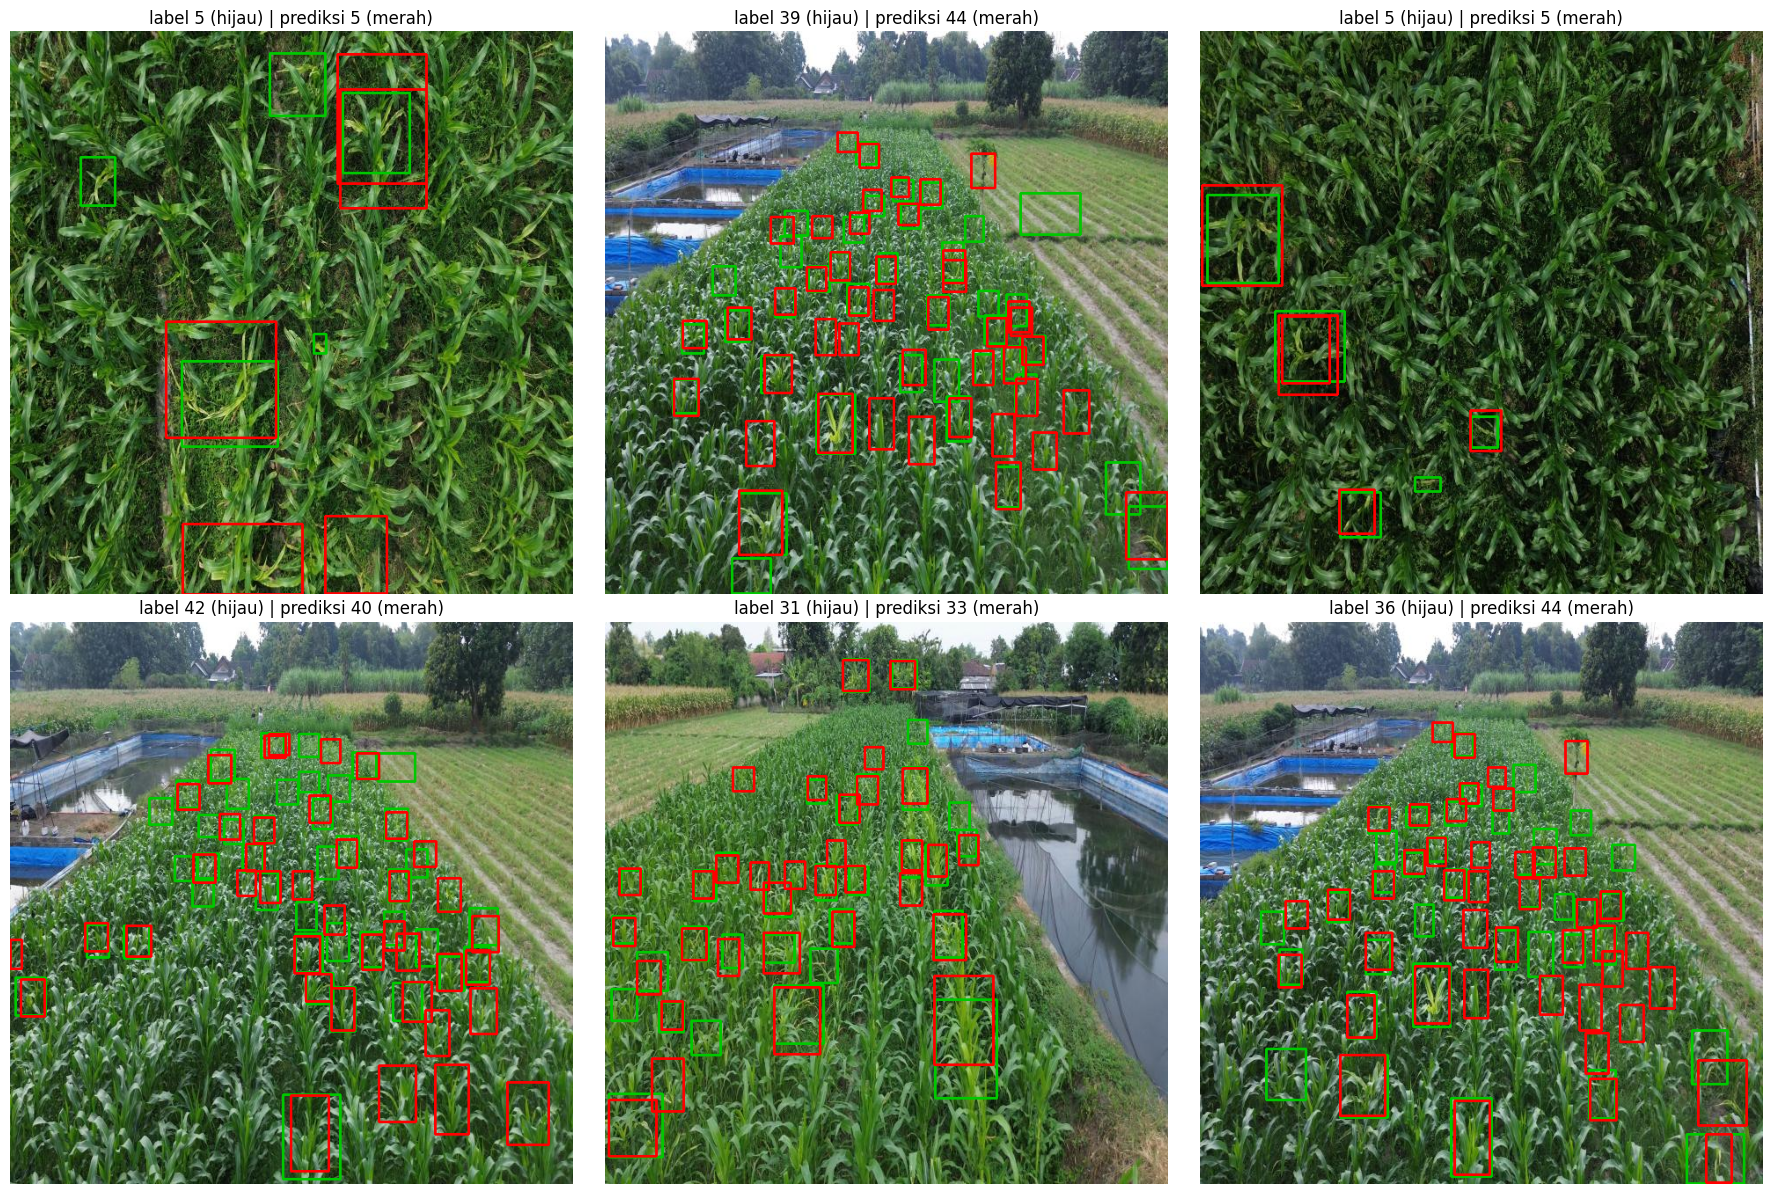

In [12]:
def baca_label(path):
    rows = []
    for line in open(path):
        p = line.split()
        if len(p) >= 5:
            rows.append([float(x) for x in p[1:5]])   # cx, cy, w, h (0-1)
    return np.array(rows, dtype=float).reshape(-1, 4)

def iou_xywh(a, b):
    ax1, ay1, ax2, ay2 = a[0]-a[2]/2, a[1]-a[3]/2, a[0]+a[2]/2, a[1]+a[3]/2
    bx1, by1, bx2, by2 = b[:,0]-b[:,2]/2, b[:,1]-b[:,3]/2, b[:,0]+b[:,2]/2, b[:,1]+b[:,3]/2
    iw = np.clip(np.minimum(ax2, bx2) - np.maximum(ax1, bx1), 0, None)
    ih = np.clip(np.minimum(ay2, by2) - np.maximum(ay1, by1), 0, None)
    inter = iw * ih
    return inter / (a[2]*a[3] + b[:,2]*b[:,3] - inter + 1e-9)

def evaluasi_gambar(pred, gt, iou_min=0.5):
    """pred: array (n,5) [cx,cy,w,h,conf]; gt: array (m,4). Pencocokan serakah berdasarkan conf."""
    tp_iou, fp_iou = [], []
    dipakai = np.zeros(len(gt), dtype=bool)
    for p in (pred[np.argsort(-pred[:, 4])] if len(pred) else []):
        if len(gt) == 0:
            fp_iou.append(0.0); continue
        o = iou_xywh(p[:4], gt)
        o_bebas = np.where(dipakai, -1, o)
        j = int(np.argmax(o_bebas))
        if o_bebas[j] >= iou_min:
            dipakai[j] = True; tp_iou.append(float(o_bebas[j]))
        else:
            fp_iou.append(float(o.max()))
    return tp_iou, fp_iou, int((~dipakai).sum())

files = sorted(glob.glob(f"{DATASET_DIR}/test/images/*"))
TP, FP, FN, per_foto = [], [], 0, []
for f in files:
    r = best.predict(f, imgsz=IMGSZ, conf=CONF, verbose=False)[0]
    xywhn = r.boxes.xywhn.cpu().numpy() if len(r.boxes) else np.zeros((0, 4))
    conf = r.boxes.conf.cpu().numpy() if len(r.boxes) else np.zeros(0)
    pred = np.c_[xywhn, conf] if len(conf) else np.zeros((0, 5))
    gt = baca_label(f.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt")
    tp, fp, fn = evaluasi_gambar(pred, gt)
    TP += tp; FP += fp; FN += fn
    per_foto.append((f, pred, gt))

n_gt = sum(len(g) for _, _, g in per_foto)
print(f"Label asli: {n_gt} | prediksi: {len(TP) + len(FP)} (conf >= {CONF:.3f})")
print(f"Benar (IoU >= 0.5): {len(TP)} | salah: {len(FP)} | label terlewat: {FN}")
print(f"Precision {len(TP)/max(len(TP)+len(FP),1):.2f} | Recall {len(TP)/max(n_gt,1):.2f}")
if TP:
    print(f"IoU kotak yang benar: median {np.median(TP):.2f}")
if FP:
    fp_arr = np.array(FP)
    print(f"Prediksi salah: {100*(fp_arr < 0.1).mean():.0f}% murni salah tempat, "
          f"{100*((fp_arr >= 0.1) & (fp_arr < 0.5)).mean():.0f}% dekat label tapi meleset")

pilih = random.sample(per_foto, min(6, len(per_foto)))
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
for ax, (f, pred, gt) in zip(axes.flat, pilih):
    im = cv2.cvtColor(cv2.imread(f), cv2.COLOR_BGR2RGB); h, w = im.shape[:2]
    for cx, cy, bw, bh in gt:
        cv2.rectangle(im, (int((cx-bw/2)*w), int((cy-bh/2)*h)), (int((cx+bw/2)*w), int((cy+bh/2)*h)), (0, 200, 0), 2)
    for cx, cy, bw, bh, c in pred:
        cv2.rectangle(im, (int((cx-bw/2)*w), int((cy-bh/2)*h)), (int((cx+bw/2)*w), int((cy+bh/2)*h)), (255, 0, 0), 2)
    ax.imshow(im); ax.axis("off"); ax.set_title(f"label {len(gt)} (hijau) | prediksi {len(pred)} (merah)")
plt.tight_layout(); plt.show()

### 5.4 Uji foto tanpa Bulai
Berapa banyak foto **tanpa Bulai** (dari `valid_negatif` dan `test_negatif`) yang tetap mendapat kotak Bulai. Ini mengukur masalah deteksi palsu di rumput atau daun sehat. Makin kecil makin baik. Untuk membandingkan dengan run lama, jalankan notebook ini dengan `RUN_TRAINING = False` dan `RUN_NAME` run lama, lalu lihat angka bagian ini.

In [15]:
neg = sorted(glob.glob(f"{DATASET_DIR}/valid_negatif/images/*") + glob.glob(f"{DATASET_DIR}/test_negatif/images/*"))
if not neg:
    print("Tidak ada foto negatif.")
else:
    jumlah = []
    for img_path in neg:
        r = best.predict(img_path, conf=CONF, imgsz=IMGSZ, verbose=False)[0]
        jumlah.append(len(r.boxes))

    n_salah = sum(n > 0 for n in jumlah)
    print(f"{n_salah} dari {len(neg)} foto tanpa Bulai ({100*n_salah/len(neg):.0f}%) tetap mendapat kotak Bulai "
          f"(total {sum(jumlah)} kotak, conf >= {CONF:.3f})")

1 dari 316 foto tanpa Bulai (0%) tetap mendapat kotak Bulai (total 1 kotak, conf >= 0.239)


## 6. Ekspor ONNX dan verifikasi
`best.pt` diubah ke ONNX (format yang dipakai backend), lalu mAP di data test dibandingkan dengan `best.pt`. Selisih mAP@50 di bawah 0.01 berarti konversi aman. Sel ini juga membuat `model_meta.json` untuk backend.

`resize_mode: "stretch"` di meta berarti foto diubah ke persegi **tanpa pita abu-abu**, sama seperti dataset v7 (Stretch 640x640). Backend perlu `detector.py` yang mendukung `resize_mode` (patch v3).

**Selesai kalau:** muncul `OK (konversi aman)` dan `Metadata tersimpan`.
> Kecepatan inferensi pada tabel hanya representatif kalau notebook ini jalan di GPU.

In [16]:
import json

if "CONF" not in globals():      # bila bagian 5.2 tidak dijalankan di sesi ini
    CONF = float(pd.read_csv(f"{DRIVE_OUT}/{RUN_NAME}_evaluasi.csv", index_col=0).loc["valid", "conf"])

WEIGHTS_DIR = f"{RUN_DIR}/weights"
best = YOLO(f"{WEIGHTS_DIR}/best.pt")

onnx_path = best.export(format="onnx", imgsz=IMGSZ, simplify=True)
print("ONNX tersimpan di:", onnx_path)

onnx_model = YOLO(onnx_path, task="detect")
m_pt   = best.val(data=YAML_PATH, split="test", imgsz=IMGSZ, batch=16, plots=False, verbose=False)
m_onnx = onnx_model.val(data=YAML_PATH, split="test", imgsz=IMGSZ, batch=1, plots=False, verbose=False)

def baris(m, path):
    return {"precision": m.box.mp, "recall": m.box.mr, "mAP50": m.box.map50, "mAP50-95": m.box.map,
            "inferensi_ms": m.speed["inference"], "ukuran_MB": os.path.getsize(path) / 1e6}

dfx = pd.DataFrame({"best.pt": baris(m_pt, f"{WEIGHTS_DIR}/best.pt"),
                    "model.onnx": baris(m_onnx, onnx_path)}).T.round(4)
print("\n=== best.pt vs ONNX (data test) ===")
print(dfx)
selisih = abs(dfx.loc["best.pt", "mAP50"] - dfx.loc["model.onnx", "mAP50"])
print(f"\nSelisih mAP50: {selisih:.4f} -> {'OK (konversi aman)' if selisih < 0.01 else 'CEK ULANG ekspor'}")
dfx.to_csv(f"{DRIVE_OUT}/{RUN_NAME}_export_verifikasi.csv")

meta = {
    "model": MODEL_NAME,
    "task": "detect",
    "onnx_file": os.path.basename(onnx_path),
    "input_size": IMGSZ,
    "classes": ["Bulai"],
    "conf_threshold": round(float(CONF), 4),
    "resize_mode": "stretch",
}
with open(f"{WEIGHTS_DIR}/model_meta.json", "w") as f:
    json.dump(meta, f, indent=2)
print("\nMetadata tersimpan di:", f"{WEIGHTS_DIR}/model_meta.json")
print(json.dumps(meta, indent=2))
print("\nSalin ke backend (ai_service/models/): best.onnx dan model_meta.json dari folder", WEIGHTS_DIR)

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 72 layers, 11,125,971 parameters, 0 gradients, 64.0 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/Dataset Bulai-YOLO/training_bulai/bulai_yolov8s_v7_bg/weights/best.pt' with input shape (1, 3, 960, 960) BCHW and output shape(s) (1, 5, 18900) (21.5 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 12 packages in 319ms
Prepared 4 packages in 508ms
Installed 4 packages in 33ms
 + colorama==0.4.6
 + onnx==1.23.2
 + onnxruntime==1.31.0
 + onnxslim==0.1.98

requirements: AutoUpdate success ✅ 1.2s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting exp

## 7. (Opsional) Diagnosis dataset
Tidak perlu untuk training atau ekspor. Dipakai untuk memahami kualitas data: ukuran kotak, kotak ganda, dan foto yang hampir sama antara train dan valid/test (contohnya frame video berurutan).

         foto    kotak  kotak/foto (rata2)  kotak/foto (maks)  sisi median (px)  % sisi < 16 px  % sisi < 32 px  % kotak tumpang tindih > 0.7
train  1309.0  24145.0                18.4               50.0              30.0             0.0            61.4                           0.0
valid   107.0   2300.0                21.5               52.0              30.4             0.0            60.0                           0.0
test     68.0   1220.0                17.9               46.0              31.0             0.1            55.7                           0.0


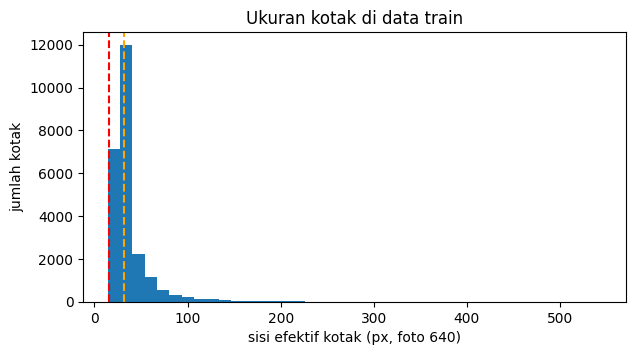

In [17]:
SISI = 640   # foto dataset berukuran 640 px
hasil, semua_sisi = {}, []
for split in ["train", "valid", "test"]:
    n_box, per_img, sisi, dobel = 0, [], [], 0
    for f in glob.glob(f"{DATASET_DIR}/{split}/labels/*.txt"):
        b = baca_label(f)
        per_img.append(len(b)); n_box += len(b)
        sisi += list(np.sqrt(b[:, 2] * b[:, 3]) * SISI)
        for i in range(len(b)):
            if len(b) > 1:
                dobel += int(iou_xywh(b[i], np.delete(b, i, axis=0)).max() > 0.7)
    sisi = np.array(sisi)
    if split == "train": semua_sisi = sisi
    hasil[split] = {
        "foto": len(per_img), "kotak": n_box,
        "kotak/foto (rata2)": round(float(np.mean(per_img)), 1), "kotak/foto (maks)": int(np.max(per_img)),
        "sisi median (px)": round(float(np.median(sisi)), 1),
        "% sisi < 16 px": round(100 * float((sisi < 16).mean()), 1),
        "% sisi < 32 px": round(100 * float((sisi < 32).mean()), 1),
        "% kotak tumpang tindih > 0.7": round(100 * dobel / max(n_box, 1), 1),
    }
pd.set_option("display.max_columns", None); pd.set_option("display.width", 200)
print(pd.DataFrame(hasil).T)

plt.figure(figsize=(7, 3.5))
plt.hist(semua_sisi, bins=40)
plt.axvline(16, color="r", ls="--"); plt.axvline(32, color="orange", ls="--")
plt.xlabel("sisi efektif kotak (px, foto 640)"); plt.ylabel("jumlah kotak"); plt.title("Ukuran kotak di data train")
plt.show()

Kotak di bawah sekitar 16 px sulit dikenali dan labelnya cenderung tidak konsisten. Persentase tumpang tindih yang tinggi berarti banyak kotak ganda atau berimpit.

In [18]:
def dhash(path, ukuran=8):
    im = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    im = cv2.resize(im, (ukuran + 1, ukuran), interpolation=cv2.INTER_AREA)
    return (im[:, 1:] > im[:, :-1]).flatten()

hash_split = {s: [dhash(p) for p in sorted(glob.glob(f"{DATASET_DIR}/{s}/images/*"))] for s in ["train", "valid", "test"]}
train_h = np.array(hash_split["train"])
for s in ["valid", "test"]:
    jarak = np.array([int((train_h != h).sum(1).min()) for h in hash_split[s]])
    print(f"{s}: {int((jarak <= 5).sum())} dari {len(jarak)} foto sangat mirip dengan foto train (jarak <= 5), "
          f"{int((jarak <= 10).sum())} cukup mirip (jarak <= 10)")

valid: 50 dari 107 foto sangat mirip dengan foto train (jarak <= 5), 87 cukup mirip (jarak <= 10)
test: 35 dari 68 foto sangat mirip dengan foto train (jarak <= 5), 56 cukup mirip (jarak <= 10)


Jarak 0 sampai 5 berarti foto yang hampir pasti sama atau berurutan. Kalau sebagian besar foto valid/test masuk kategori itu, angka mAP terlalu optimis.